In [4]:
#Task1
import torch
import torchvision
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision imported successfully!")

PyTorch version: 2.14.0+cpu
Torchvision imported successfully!


In [8]:
#Task2
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Dataset loaded successfully!")

Training images: 60000
Testing images: 10000
Dataset loaded successfully!


In [3]:
images, labels = next(iter(train_loader))

print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)

Images tensor size: torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])


In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap='gray')
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [1]:
import matplotlib
print("Matplotlib version:", matplotlib.__version__)

import matplotlib.pyplot as plt
print("Matplotlib imported successfully!")

Matplotlib version: 3.10.0
Matplotlib imported successfully!


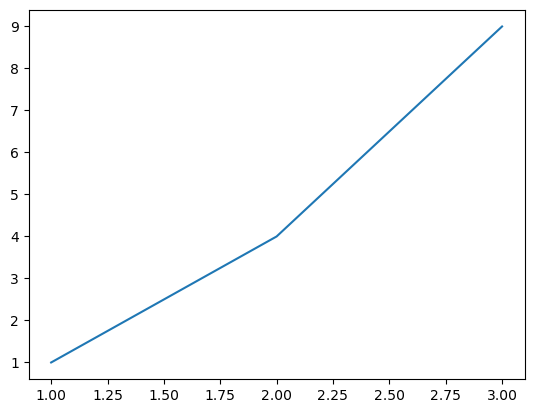

In [2]:
plt.plot([1, 2, 3], [1, 4, 9])
plt.show()

In [9]:
images, labels = next(iter(train_loader))

print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)

Images tensor size: torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])


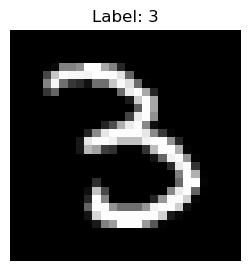

In [10]:
plt.figure(figsize=(3, 3))
plt.imshow(images[0].squeeze().numpy(), cmap='gray')
plt.title(f"Label: {labels[0].item()}")
plt.axis('off')
plt.show()


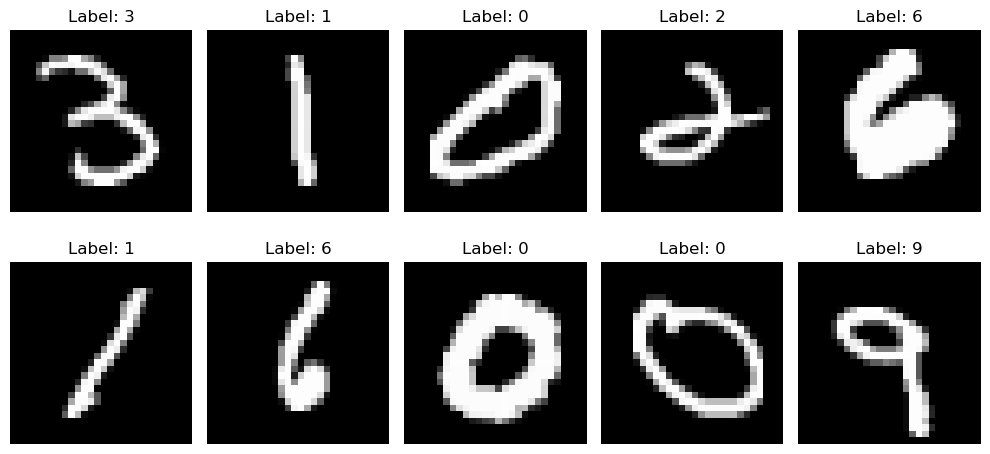

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze().numpy(), cmap='gray')
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [12]:
#Task4
import torch.nn as nn

class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()

        self.fc1 = nn.Linear(784, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

model = SimpleNN()
print(model)


SimpleNN(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [13]:
sample_images, sample_labels = next(iter(train_loader))

outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Flattened shape:", torch.flatten(sample_images, start_dim=1).shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 1, 28, 28])
Flattened shape: torch.Size([32, 784])
Output shape: torch.Size([32, 10])


In [15]:
#Task5
import torch.optim as optim

def train(model, train_loader, epochs=5, learning_rate=0.01, momentum=0.9):

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=momentum)

    all_losses = []
    epoch_losses = []
    epoch_accuracies = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for batch_idx, (images, labels) in enumerate(train_loader):

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            all_losses.append(loss.item())

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            if (batch_idx + 1) % 200 == 0:
                print(f"Epoch [{epoch+1}/{epochs}], "
                      f"Batch [{batch_idx+1}/{len(train_loader)}], "
                      f"Loss: {loss.item():.4f}, "
                      f"Accuracy: {100 * correct / total:.2f}%")

        avg_loss = running_loss / len(train_loader)
        accuracy = 100 * correct / total

        epoch_losses.append(avg_loss)
        epoch_accuracies.append(accuracy)

        print(f"Epoch {epoch+1} completed - "
              f"Loss: {avg_loss:.4f}, Accuracy: {accuracy:.2f}%")

    return all_losses, epoch_losses, epoch_accuracies

In [16]:
#Task6
# Task 6: Training Network

model = SimpleNN()

all_losses, epoch_losses, epoch_accuracies = train(
    model,
    train_loader,
    epochs=5,
    learning_rate=0.01,
    momentum=0.9
)

Epoch [1/5], Batch [200/1875], Loss: 0.4743, Accuracy: 74.56%
Epoch [1/5], Batch [400/1875], Loss: 0.3861, Accuracy: 81.37%
Epoch [1/5], Batch [600/1875], Loss: 0.1384, Accuracy: 84.32%
Epoch [1/5], Batch [800/1875], Loss: 0.5691, Accuracy: 86.06%
Epoch [1/5], Batch [1000/1875], Loss: 0.1204, Accuracy: 87.16%
Epoch [1/5], Batch [1200/1875], Loss: 0.2285, Accuracy: 87.97%
Epoch [1/5], Batch [1400/1875], Loss: 0.3020, Accuracy: 88.67%
Epoch [1/5], Batch [1600/1875], Loss: 0.1073, Accuracy: 89.20%
Epoch [1/5], Batch [1800/1875], Loss: 0.0736, Accuracy: 89.71%
Epoch 1 completed - Loss: 0.3602, Accuracy: 89.90%
Epoch [2/5], Batch [200/1875], Loss: 0.0641, Accuracy: 94.58%
Epoch [2/5], Batch [400/1875], Loss: 0.2083, Accuracy: 94.52%
Epoch [2/5], Batch [600/1875], Loss: 0.1196, Accuracy: 94.71%
Epoch [2/5], Batch [800/1875], Loss: 0.1286, Accuracy: 94.79%
Epoch [2/5], Batch [1000/1875], Loss: 0.1882, Accuracy: 94.92%
Epoch [2/5], Batch [1200/1875], Loss: 0.1657, Accuracy: 94.99%
Epoch [2/5],

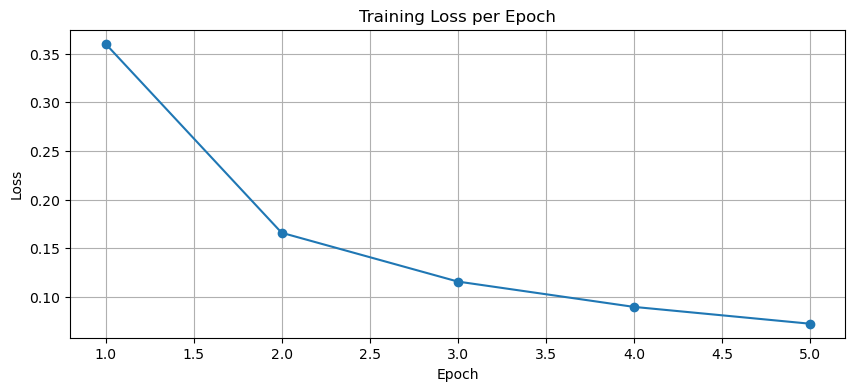

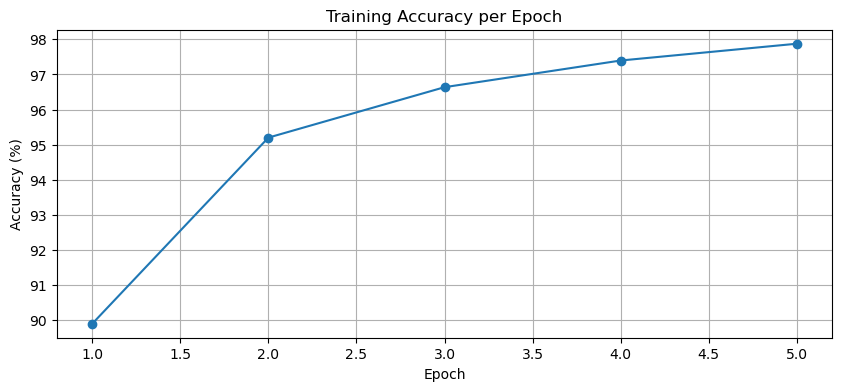

In [17]:
# Task 6: Training Results

plt.figure(figsize=(10, 4))
plt.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss per Epoch")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(range(1, len(epoch_accuracies) + 1), epoch_accuracies, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training Accuracy per Epoch")
plt.grid(True)
plt.show()

In [18]:
# Task 7: Testing Network

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 97.39%


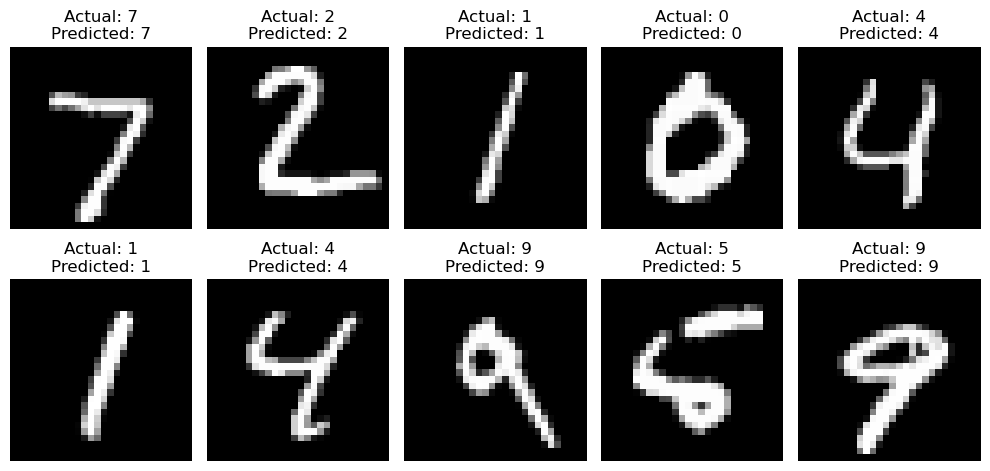

In [19]:
# Task 7: Visualize Predictions

model.eval()

test_images, test_labels = next(iter(test_loader))

with torch.no_grad():
    outputs = model(test_images)
    _, predictions = torch.max(outputs, 1)

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(test_images[i].squeeze().numpy(), cmap='gray')
    ax.set_title(
        f"Actual: {test_labels[i].item()}\n"
        f"Predicted: {predictions[i].item()}"
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

In [20]:
# Task 8: Hyperparameter Tuning

import pandas as pd

experiments = [
    (0.01, 0.9),
    (0.001, 0.9),
    (0.01, 0.5)
]

results = []

for lr, mom in experiments:
    print(f"\nTraining with LR={lr}, Momentum={mom}")

    tuned_model = SimpleNN()

    losses, epoch_loss, epoch_acc = train(
        tuned_model,
        train_loader,
        epochs=5,
        learning_rate=lr,
        momentum=mom
    )

    tuned_model.eval()
    correct = 0
    total = 0
    test_loss = 0.0
    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = tuned_model(images)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    results.append({
        "Learning Rate": lr,
        "Momentum": mom,
        "Test Loss": test_loss / total,
        "Test Accuracy": 100 * correct / total
    })

results_df = pd.DataFrame(results)
print("\nHyperparameter Tuning Results:")
print(results_df.to_string(index=False))




Training with LR=0.01, Momentum=0.9
Epoch [1/5], Batch [200/1875], Loss: 0.3731, Accuracy: 72.86%
Epoch [1/5], Batch [400/1875], Loss: 0.1587, Accuracy: 80.48%
Epoch [1/5], Batch [600/1875], Loss: 0.6195, Accuracy: 83.85%
Epoch [1/5], Batch [800/1875], Loss: 0.1831, Accuracy: 85.61%
Epoch [1/5], Batch [1000/1875], Loss: 0.1996, Accuracy: 86.77%
Epoch [1/5], Batch [1200/1875], Loss: 0.1509, Accuracy: 87.64%
Epoch [1/5], Batch [1400/1875], Loss: 0.0914, Accuracy: 88.51%
Epoch [1/5], Batch [1600/1875], Loss: 0.1290, Accuracy: 89.04%
Epoch [1/5], Batch [1800/1875], Loss: 0.1095, Accuracy: 89.58%
Epoch 1 completed - Loss: 0.3604, Accuracy: 89.77%
Epoch [2/5], Batch [200/1875], Loss: 0.3647, Accuracy: 94.72%
Epoch [2/5], Batch [400/1875], Loss: 0.2677, Accuracy: 94.52%
Epoch [2/5], Batch [600/1875], Loss: 0.0918, Accuracy: 94.77%
Epoch [2/5], Batch [800/1875], Loss: 0.0927, Accuracy: 94.87%
Epoch [2/5], Batch [1000/1875], Loss: 0.1043, Accuracy: 94.98%
Epoch [2/5], Batch [1200/1875], Loss: 

In [21]:
# Task 8: Architecture Tuning

class TunableNN(nn.Module):
    def __init__(self, hidden_layers):
        super(TunableNN, self).__init__()

        layers = []
        input_size = 784

        for neurons in hidden_layers:
            layers.append(nn.Linear(input_size, neurons))
            layers.append(nn.ReLU())
            input_size = neurons

        layers.append(nn.Linear(input_size, 10))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        return self.network(x)

In [22]:
# Task 8: Compare Architectures

architectures = [
    [64],
    [128],
    [128, 64]
]

architecture_results = []

for hidden_layers in architectures:
    print(f"\nTraining architecture: {hidden_layers}")

    tuned_model = TunableNN(hidden_layers)

    losses, epoch_loss, epoch_acc = train(
        tuned_model,
        train_loader,
        epochs=5,
        learning_rate=0.01,
        momentum=0.9
    )

    tuned_model.eval()
    correct = 0
    total = 0
    test_loss = 0.0
    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = tuned_model(images)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    architecture_results.append({
        "Hidden Layers": str(hidden_layers),
        "Number of Layers": len(hidden_layers),
        "Test Loss": test_loss / total,
        "Test Accuracy": 100 * correct / total
    })

architecture_df = pd.DataFrame(architecture_results)

print("\nArchitecture Tuning Results:")
print(architecture_df.to_string(index=False))


Training architecture: [64]
Epoch [1/5], Batch [200/1875], Loss: 0.5969, Accuracy: 71.16%
Epoch [1/5], Batch [400/1875], Loss: 0.4231, Accuracy: 79.39%
Epoch [1/5], Batch [600/1875], Loss: 0.1535, Accuracy: 82.89%
Epoch [1/5], Batch [800/1875], Loss: 0.3300, Accuracy: 84.82%
Epoch [1/5], Batch [1000/1875], Loss: 0.6211, Accuracy: 86.15%
Epoch [1/5], Batch [1200/1875], Loss: 0.0606, Accuracy: 87.07%
Epoch [1/5], Batch [1400/1875], Loss: 0.4890, Accuracy: 87.87%
Epoch [1/5], Batch [1600/1875], Loss: 0.3431, Accuracy: 88.46%
Epoch [1/5], Batch [1800/1875], Loss: 0.2548, Accuracy: 88.97%
Epoch 1 completed - Loss: 0.3746, Accuracy: 89.09%
Epoch [2/5], Batch [200/1875], Loss: 0.1423, Accuracy: 93.66%
Epoch [2/5], Batch [400/1875], Loss: 0.1345, Accuracy: 93.43%
Epoch [2/5], Batch [600/1875], Loss: 0.3212, Accuracy: 93.82%
Epoch [2/5], Batch [800/1875], Loss: 0.1406, Accuracy: 94.08%
Epoch [2/5], Batch [1000/1875], Loss: 0.2171, Accuracy: 94.17%
Epoch [2/5], Batch [1200/1875], Loss: 0.2184, 